
# Task 02: California Housing Price Prediction

## Project Overview

This project focuses on predicting median house values in California using supervised Machine Learning regression algorithms.

The goal is to develop, train, and compare multiple regression models to identify the best-performing model.

## Project Objectives

- Load and explore the California Housing dataset.
- Perform Exploratory Data Analysis (EDA).
- Handle missing values.
- Analyze correlations and multicollinearity.
- Perform Feature Engineering and create interaction features.
- Apply feature scaling and preprocessing.
- Train Linear Regression, Ridge, and Lasso models.
- Optimize hyperparameters using GridSearchCV.
- Evaluate models using RMSE, MAE, and R².
- Visualize predictions and residual errors.

## Machine Learning Models

1. Linear Regression (OLS)
2. Ridge Regression (L2 Regularization)
3. Lasso Regression (L1 Regularization)

## Evaluation Metrics

- Root Mean Squared Error (RMSE)
- Mean Absolute Error (MAE)
- R² Score


# 1. Import Libraries

Import the required libraries for data analysis, visualization, preprocessing, model training, and evaluation.

In [1]:

# Data Manipulation
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data Preprocessing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Regression Models
from sklearn.linear_model import LinearRegression, Ridge, Lasso

# Evaluation Metrics
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# Visualization Settings
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("All libraries imported successfully!")


All libraries imported successfully!


## 2. Data Loading

In [2]:

# Dataset URL
url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"

# Load Dataset
df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset Shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY



## 3. Data Inspection

In this section, we will inspect the dataset structure, column names, data types, and statistical information to understand the available features.


In [6]:
# Display Dataset Information

print("DATASET INFORMATION")
print("=" * 60)

print("\nDataset Shape:")
print(df.shape)
print()
print("=" * 60)

print("\nColumn Names:")
print(df.columns.tolist())
print()
print("=" * 60)

print("\nDataset Info:")
df.info()


DATASET INFORMATION

Dataset Shape:
(20640, 10)


Column Names:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']


Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB



### 3.1 Statistical Summary

Generate descriptive statistics to understand the distribution, range, and variation of numerical features.


In [7]:

# Statistical Summary

df.describe().T


,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000



### 3.2 Missing Values Analysis

Identify missing values in each column and visualize their distribution to determine the appropriate imputation strategy.


In [8]:

# Calculate Missing Values

missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (missing_values / len(df)) * 100
})

missing_summary = missing_summary.sort_values(
    by="Missing Values",
    ascending=False
)

missing_summary


,Missing Values,Missing Percentage
total_bedrooms,207,1.002907
longitude,0,0.000000
latitude,0,0.000000
housing_median_age,0,0.000000
total_rooms,0,0.000000
population,0,0.000000
households,0,0.000000
median_income,0,0.000000
median_house_value,0,0.000000
ocean_proximity,0,0.000000



### 3.3 Missing Values Visualization

Visualize the number of missing values in each feature using a bar chart.


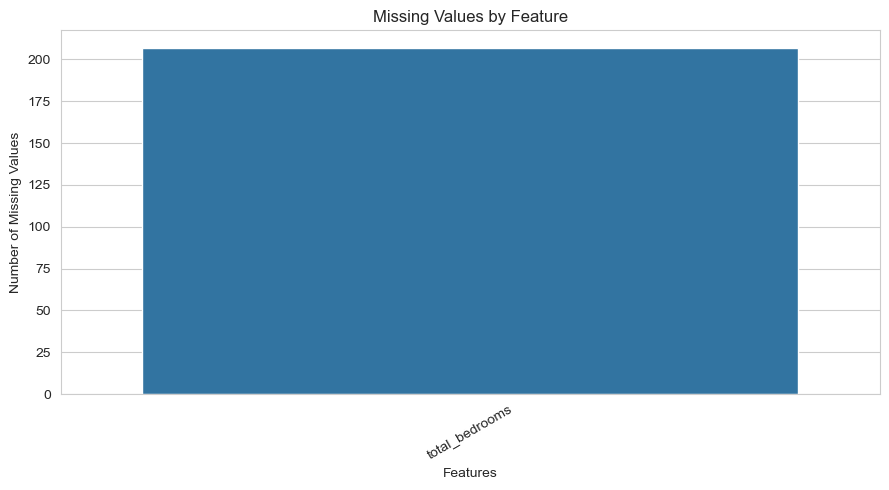

In [9]:

# Plot Missing Values

missing_counts = df.isnull().sum()
missing_counts = missing_counts[missing_counts > 0]

plt.figure(figsize=(9, 5))

sns.barplot(
    x=missing_counts.index,
    y=missing_counts.values
)

plt.title("Missing Values by Feature")
plt.xlabel("Features")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()



### 3.4 Duplicate Values Analysis

Check whether the dataset contains duplicate records that may affect model training.


In [10]:

# Check Duplicate Rows

duplicate_count = df.duplicated().sum()

print("Number of Duplicate Rows:", duplicate_count)


Number of Duplicate Rows: 0


## 4. Exploratory Data Analysis(EDA)

### 4.1 Target Variable Distribution

Analyze the distribution of median house values to understand the target variable and identify potential outliers or value limitations.


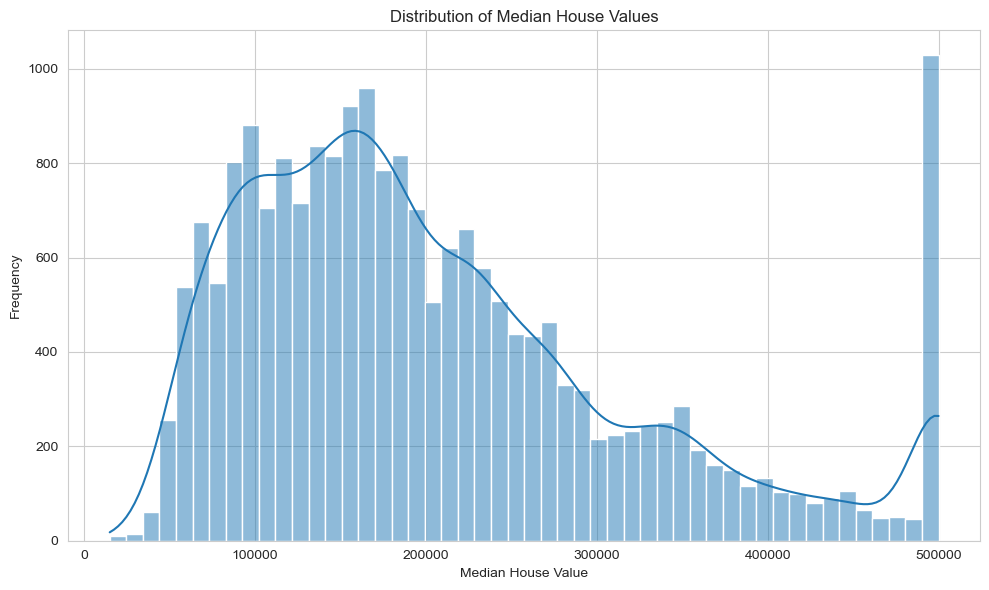

In [11]:

# Target Variable Distribution

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="median_house_value",
    bins=50,
    kde=True
)

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()



### 4.2 Numerical Features Distribution

Visualize the distributions of numerical features to understand their ranges, skewness, and potential outliers.


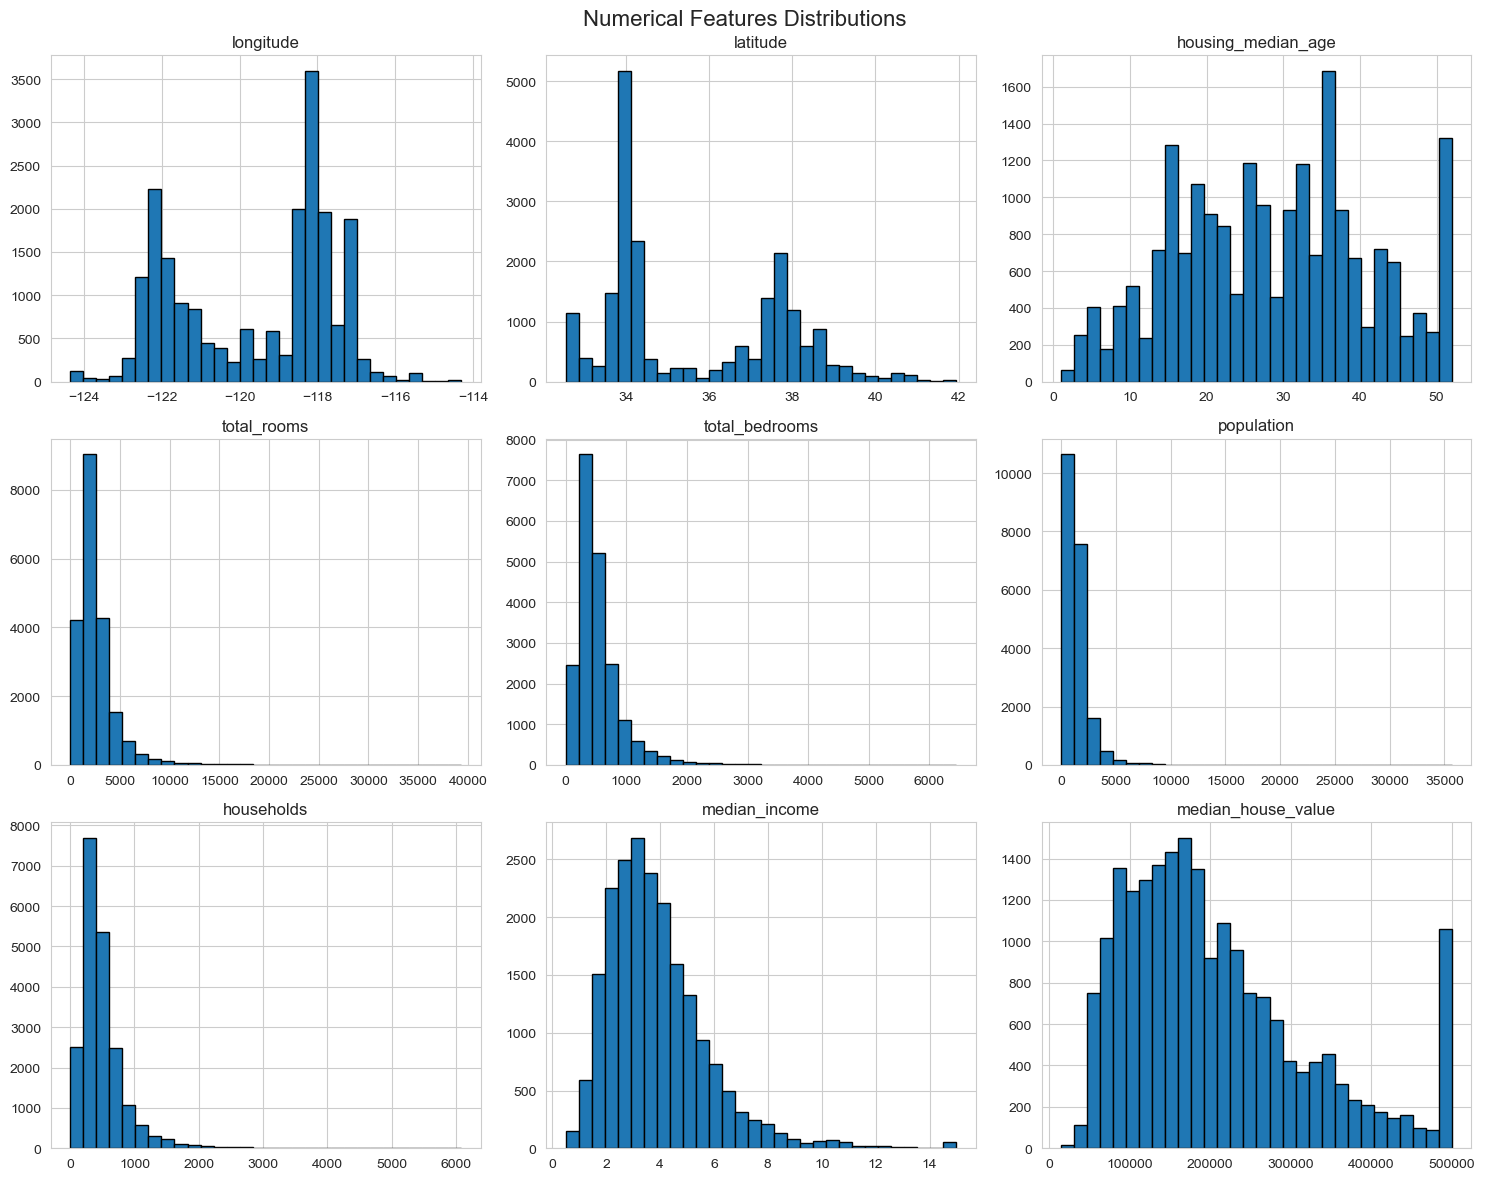

In [12]:

# Select Numerical Features

numerical_columns = df.select_dtypes(
    include=np.number
).columns

# Plot Numerical Distributions

df[numerical_columns].hist(
    figsize=(15, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Numerical Features Distributions", fontsize=16)
plt.tight_layout()
plt.show()



### 4.3 Categorical Feature Analysis

Analyze the distribution of housing districts across different ocean proximity categories.


Ocean Proximity Distribution:
ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


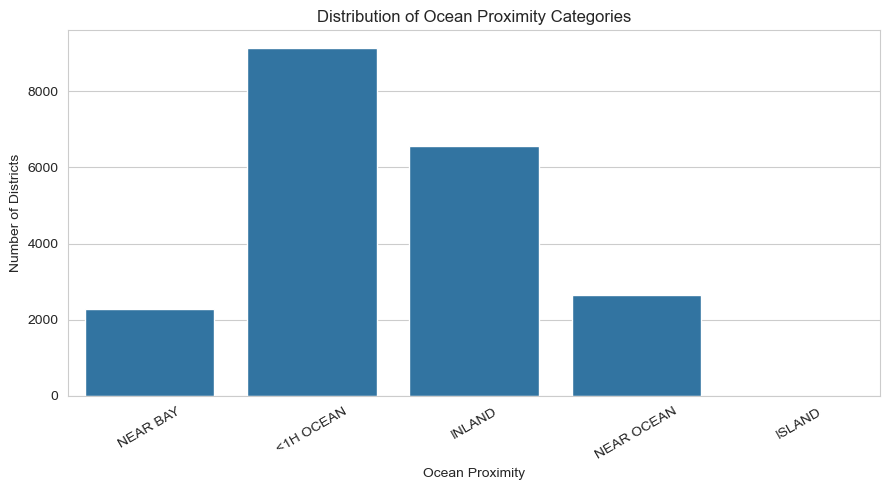

In [13]:

# Analyze Ocean Proximity Categories

print("Ocean Proximity Distribution:")
print(df["ocean_proximity"].value_counts())

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="ocean_proximity"
)

plt.title("Distribution of Ocean Proximity Categories")
plt.xlabel("Ocean Proximity")
plt.ylabel("Number of Districts")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()



## 5. Correlation Analysis

Analyze the relationships between numerical features using a correlation matrix to identify important features and potential multicollinearity.


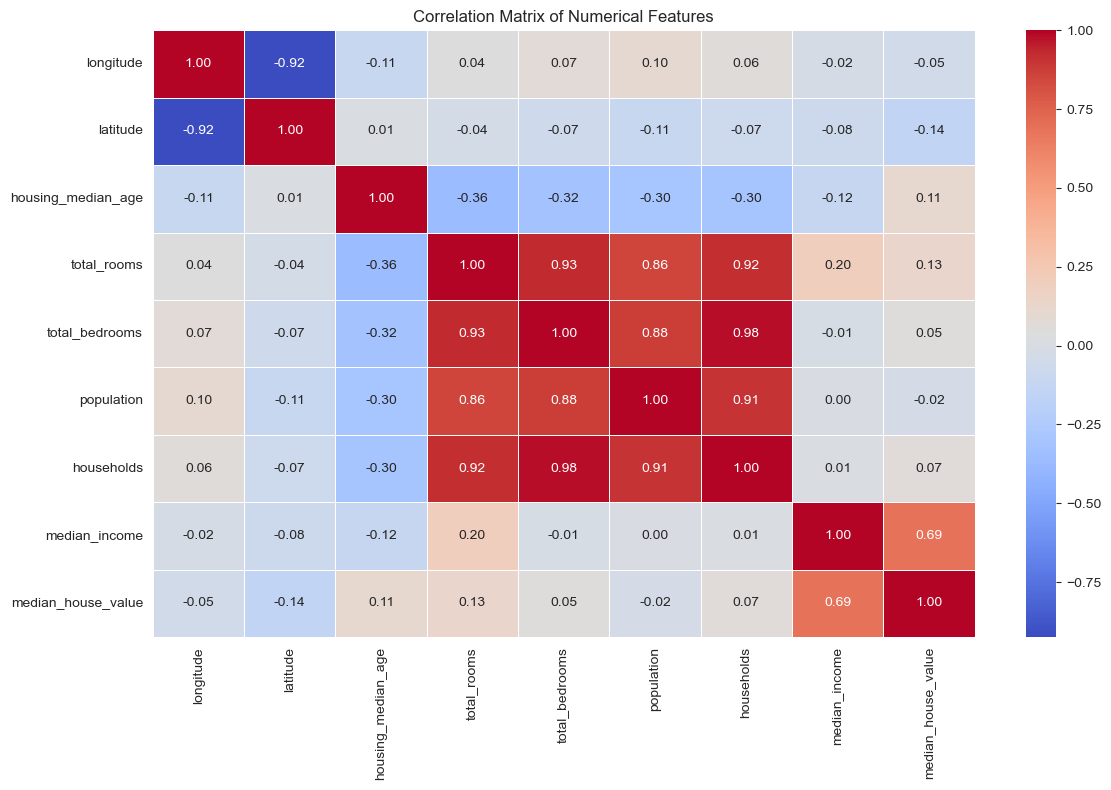

In [14]:

# Calculate Numerical Correlations

correlation_matrix = df.select_dtypes(
    include=np.number
).corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()



### 5.1 Feature Correlation with Target Variable

Examine the correlation between numerical features and median house values to identify potentially influential predictors.


Correlation with Median House Value:


median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64

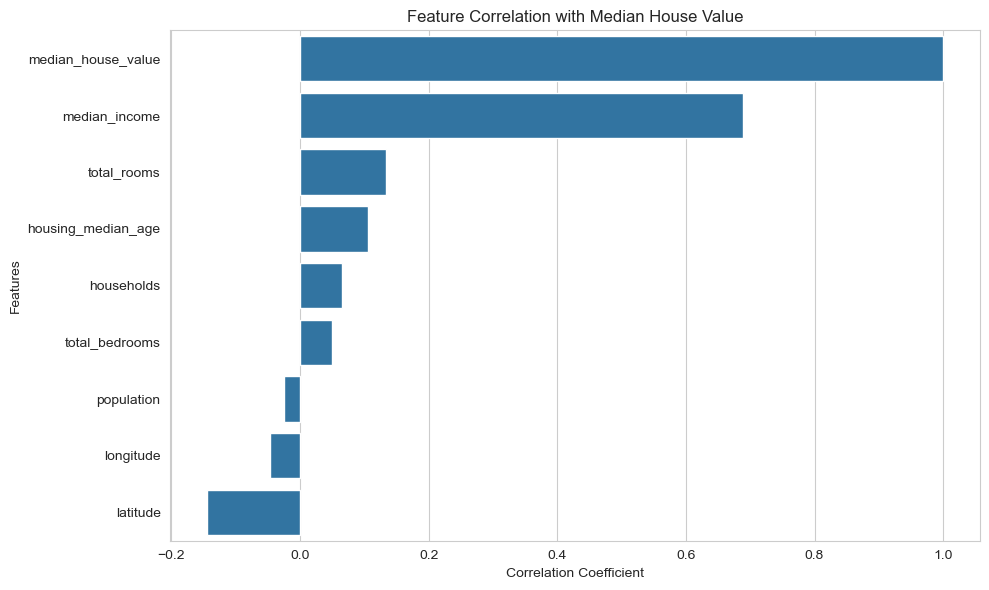

In [15]:

# Correlation with Target Variable

target_correlation = correlation_matrix["median_house_value"]

target_correlation = target_correlation.sort_values(
    ascending=False
)

print("Correlation with Median House Value:")
display(target_correlation)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=target_correlation.values,
    y=target_correlation.index
)

plt.title("Feature Correlation with Median House Value")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Features")
plt.tight_layout()
plt.show()



### 5.2 Geographic Distribution of House Values

Visualize the geographical distribution of housing districts using longitude and latitude, with color representing median house values.


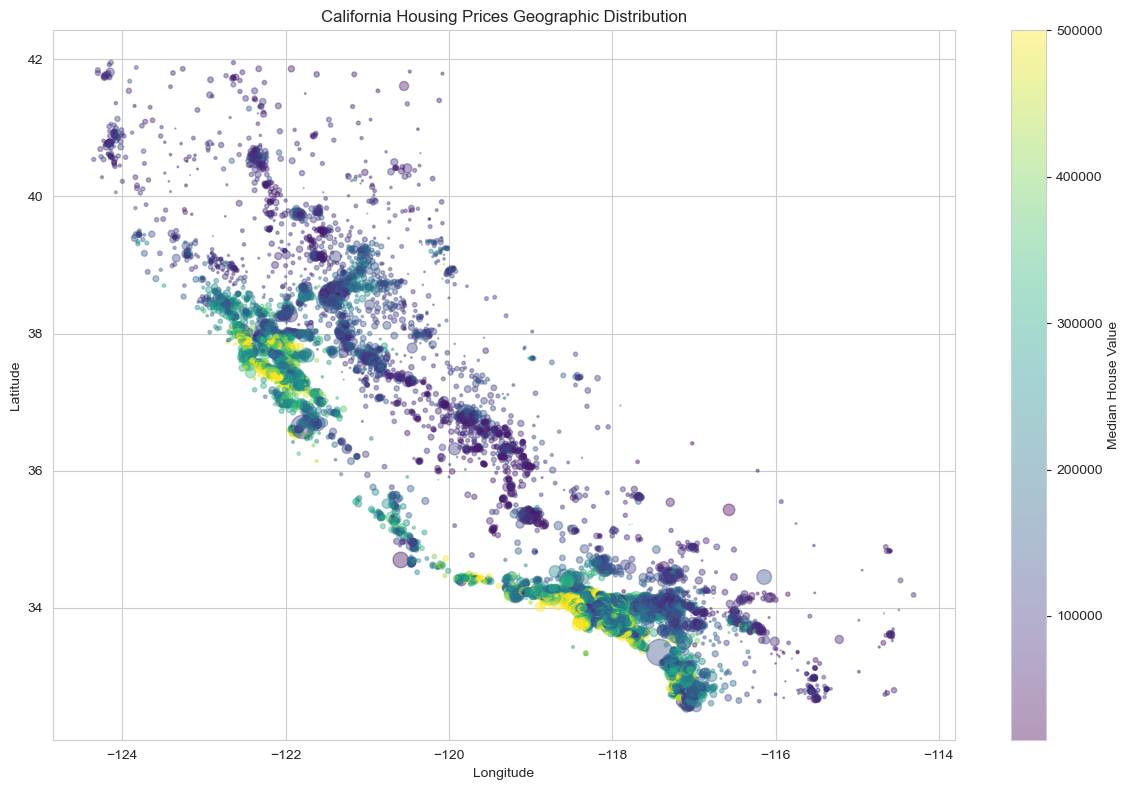

In [16]:

# Geographic Distribution

plt.figure(figsize=(12, 8))

scatter = plt.scatter(
    df["longitude"],
    df["latitude"],
    c=df["median_house_value"],
    cmap="viridis",
    alpha=0.4,
    s=df["population"] / 100
)

plt.colorbar(
    scatter,
    label="Median House Value"
)

plt.title("California Housing Prices Geographic Distribution")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()



## 6. Data Preprocessing

Separate the input features from the target variable before preparing the data for model training.


In [17]:

# Separate Features and Target

X = df.drop("median_house_value", axis=1)
y = df["median_house_value"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)


Features Shape: (20640, 9)
Target Shape: (20640,)



### 6.1 Train-Test Split

Split the dataset into training and testing sets to evaluate model performance on unseen data.


In [18]:

# Split Dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)


Training Features: (16512, 9)
Testing Features: (4128, 9)
Training Target: (16512,)
Testing Target: (4128,)



### 6.2 Feature Engineering

Create meaningful interaction and ratio-based features to improve the predictive power of the regression models.

The engineered features include:

- Rooms per Household
- Bedrooms per Room
- Population per Household


In [19]:

# Feature Engineering Function

def create_features(data):
    data = data.copy()

    data["rooms_per_household"] = (
        data["total_rooms"] / data["households"]
    )

    data["bedrooms_per_room"] = (
        data["total_bedrooms"] / data["total_rooms"]
    )

    data["population_per_household"] = (
        data["population"] / data["households"]
    )

    return data


# Apply Feature Engineering

X_train = create_features(X_train)
X_test = create_features(X_test)

print("Feature Engineering Completed!")
print("New Training Shape:", X_train.shape)
print("New Testing Shape:", X_test.shape)

X_train.head()


Feature Engineering Completed!
New Training Shape: (16512, 12)
New Testing Shape: (4128, 12)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household
14196,-117.03,32.71,33.0,3126.0,627.0,2300.0,623.0,3.2596,NEAR OCEAN,5.017657,0.200576,3.691814
8267,-118.16,33.77,49.0,3382.0,787.0,1314.0,756.0,3.8125,NEAR OCEAN,4.473545,0.232703,1.738095
17445,-120.48,34.66,4.0,1897.0,331.0,915.0,336.0,4.1563,NEAR OCEAN,5.645833,0.174486,2.723214
14265,-117.11,32.69,36.0,1421.0,367.0,1418.0,355.0,1.9425,NEAR OCEAN,4.002817,0.258269,3.994366
2271,-119.80,36.78,43.0,2382.0,431.0,874.0,380.0,3.5542,INLAND,6.268421,0.180940,2.300000



### 6.3 Identify Numerical and Categorical Features

Separate numerical and categorical columns to apply appropriate preprocessing techniques to each feature type.


In [20]:

# Identify Feature Types

numerical_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)


Numerical Features:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household']

Categorical Features:
['ocean_proximity']



## 7. Preprocessing Pipeline

Build a preprocessing pipeline that handles missing values, scales numerical features, and encodes categorical features.

- Numerical features: Median Imputation + StandardScaler.
- Categorical features: Most Frequent Imputation + OneHotEncoder.


In [21]:

# Numerical Preprocessing Pipeline

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


# Categorical Preprocessing Pipeline

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


# Combine Preprocessing Pipelines

preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])


print("Preprocessing Pipeline Created Successfully!")


Preprocessing Pipeline Created Successfully!



## 8. Model Training

### 8.1 Linear Regression (Ordinary Least Squares)

Train a Linear Regression model using the preprocessing pipeline to establish a baseline for predicting California median house values.


In [22]:

# Build Linear Regression Pipeline

linear_regression_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

# Train the Model

linear_regression_model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")


Linear Regression Model Trained Successfully!



### 8.2 Ridge Regression (L2 Regularization)

Train a Ridge Regression model to reduce the impact of large coefficients and improve model generalization using L2 regularization.


In [23]:

# Build Ridge Regression Pipeline

ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge())
])

# Train the Initial Ridge Model

ridge_pipeline.fit(X_train, y_train)

print("Ridge Regression Model Trained Successfully!")


Ridge Regression Model Trained Successfully!



### 8.3 Lasso Regression (L1 Regularization)

Train a Lasso Regression model using L1 regularization, which can shrink some feature coefficients to zero and perform implicit feature selection.


In [24]:

# Build Lasso Regression Pipeline

lasso_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Lasso(max_iter=10000))
])

# Train the Initial Lasso Model

lasso_pipeline.fit(X_train, y_train)

print("Lasso Regression Model Trained Successfully!")


Lasso Regression Model Trained Successfully!



## 9. Hyperparameter Optimization

### 9.1 Ridge Regression Optimization

Use GridSearchCV with cross-validation to identify the optimal alpha value for Ridge Regression.


In [25]:

# Ridge Hyperparameter Grid

ridge_param_grid = {
    "model__alpha": [0.01, 0.1, 1, 10, 100, 1000]
}

# Grid Search with Cross-Validation

ridge_grid_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

ridge_grid_search.fit(X_train, y_train)

best_ridge_model = ridge_grid_search.best_estimator_

print("Best Ridge Alpha:", ridge_grid_search.best_params_["model__alpha"])
print("Best Ridge CV RMSE:", -ridge_grid_search.best_score_)


Best Ridge Alpha: 1
Best Ridge CV RMSE: 67847.5855222602



### 9.2 Lasso Regression Optimization

Use GridSearchCV to find the optimal alpha value for Lasso Regression based on cross-validation RMSE.


In [26]:

# Lasso Hyperparameter Grid

lasso_param_grid = {
    "model__alpha": [0.01, 0.1, 1, 10, 100, 1000]
}

# Grid Search with Cross-Validation

lasso_grid_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=lasso_param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

lasso_grid_search.fit(X_train, y_train)

best_lasso_model = lasso_grid_search.best_estimator_

print("Best Lasso Alpha:", lasso_grid_search.best_params_["model__alpha"])
print("Best Lasso CV RMSE:", -lasso_grid_search.best_score_)


Best Lasso Alpha: 1
Best Lasso CV RMSE: 67848.71226030537



## 10. Model Evaluation

### 10.1 Generate Predictions

Generate predictions for the test dataset using the trained Linear Regression model and the optimized Ridge and Lasso models.


In [27]:

# Generate Test Predictions

y_pred_linear = linear_regression_model.predict(X_test)

y_pred_ridge = best_ridge_model.predict(X_test)

y_pred_lasso = best_lasso_model.predict(X_test)

print("Predictions Generated Successfully!")
print("Linear Regression:", len(y_pred_linear))
print("Ridge Regression:", len(y_pred_ridge))
print("Lasso Regression:", len(y_pred_lasso))


Predictions Generated Successfully!
Linear Regression: 4128
Ridge Regression: 4128
Lasso Regression: 4128



### 10.2 Evaluation Metrics

Evaluate each model using:

- RMSE: Measures the square root of average squared prediction errors.
- MAE: Measures the average absolute prediction error.
- R² Score: Measures the proportion of target variance explained by the model.


In [28]:

# Define Evaluation Function

def evaluate_regression_model(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    return {
        "RMSE": rmse,
        "MAE": mae,
        "R2 Score": r2
    }


# Evaluate All Models

linear_metrics = evaluate_regression_model(y_test, y_pred_linear)

ridge_metrics = evaluate_regression_model(y_test, y_pred_ridge)

lasso_metrics = evaluate_regression_model(y_test, y_pred_lasso)


print("Linear Regression:", linear_metrics)
print("Ridge Regression:", ridge_metrics)
print("Lasso Regression:", lasso_metrics)


Linear Regression: {'RMSE': np.float64(69127.03829924985), 'MAE': 49645.49244453642, 'R2 Score': 0.635339233523819}
Ridge Regression: {'RMSE': np.float64(69134.96527371784), 'MAE': 49652.1428727252, 'R2 Score': 0.6352555955611361}
Lasso Regression: {'RMSE': np.float64(69128.09124072842), 'MAE': 49646.42889325857, 'R2 Score': 0.6353281244301747}



### 10.3 Model Performance Comparison

Compare the performance of all three regression models using RMSE, MAE, and R² Score to identify the best-performing model.


In [29]:

# Create Model Comparison DataFrame

comparison_df = pd.DataFrame([
    {"Model": "Linear Regression", **linear_metrics},
    {"Model": "Ridge Regression", **ridge_metrics},
    {"Model": "Lasso Regression", **lasso_metrics}
])

comparison_df = comparison_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

comparison_df


,Model,RMSE,MAE,R2 Score
0,Linear Regression,69127.038299,49645.492445,0.635339
1,Lasso Regression,69128.091241,49646.428893,0.635328
2,Ridge Regression,69134.965274,49652.142873,0.635256



## 11. Model Visualization

### 11.1 Actual vs Predicted Values

Visualize the relationship between actual and predicted house values for each regression model. A closer alignment with the diagonal reference line indicates better predictions.


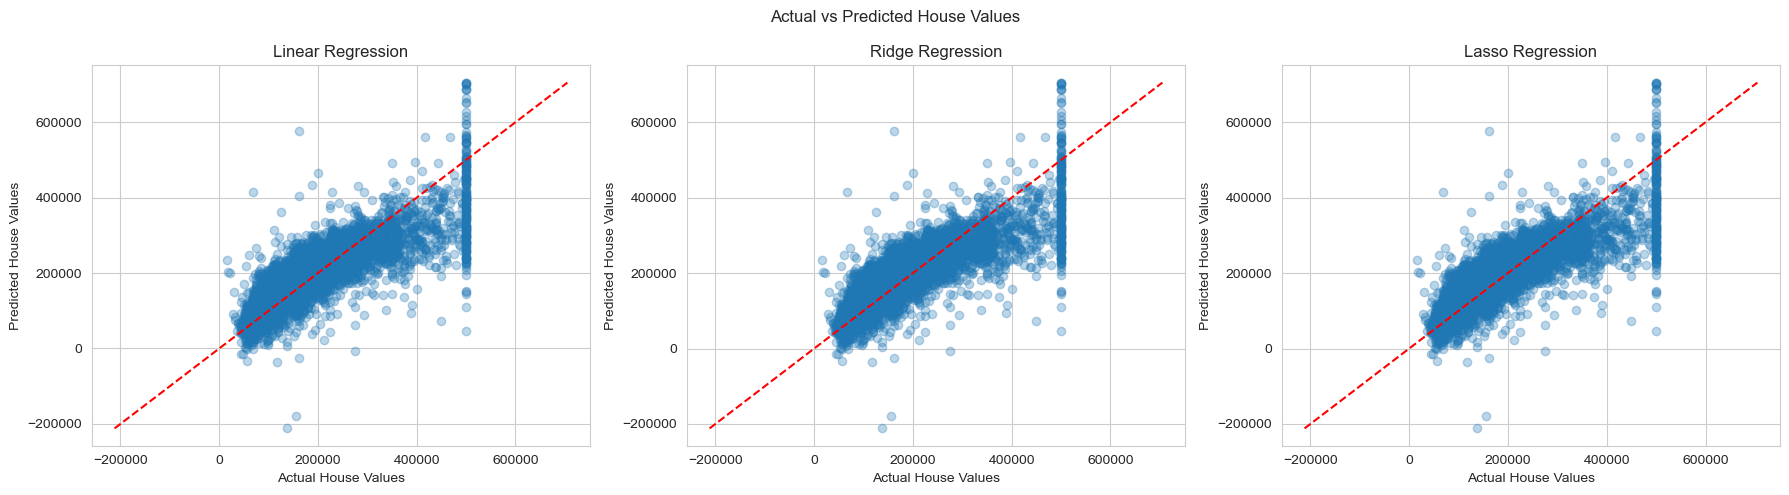

In [30]:

# Actual vs Predicted Visualization

predictions = {
    "Linear Regression": y_pred_linear,
    "Ridge Regression": y_pred_ridge,
    "Lasso Regression": y_pred_lasso
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (model_name, predictions_values) in zip(
    axes, predictions.items()
):
    ax.scatter(
        y_test,
        predictions_values,
        alpha=0.3
    )

    min_value = min(y_test.min(), predictions_values.min())
    max_value = max(y_test.max(), predictions_values.max())

    ax.plot(
        [min_value, max_value],
        [min_value, max_value],
        "r--"
    )

    ax.set_title(model_name)
    ax.set_xlabel("Actual House Values")
    ax.set_ylabel("Predicted House Values")

plt.suptitle("Actual vs Predicted House Values")
plt.tight_layout()
plt.show()



### 11.2 Residual Distribution Analysis

Analyze the distribution of residual errors for each model to understand prediction errors and identify possible systematic patterns.


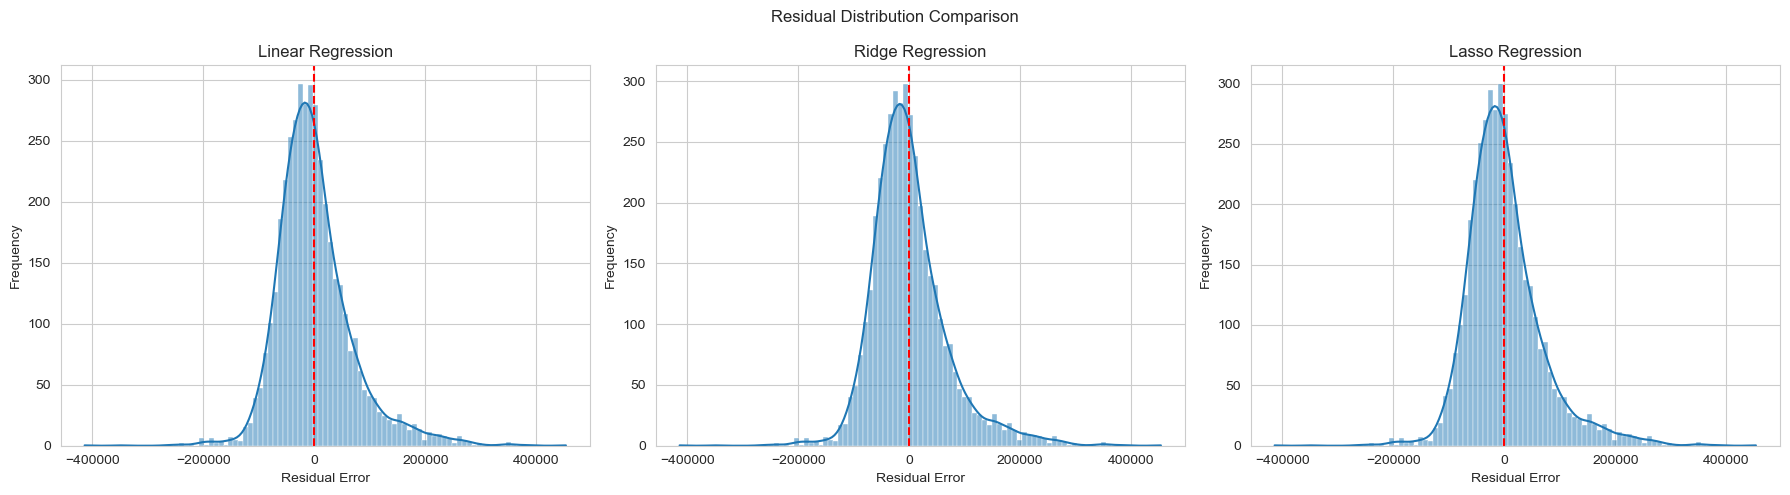

In [31]:

# Calculate Residuals

residuals = {
    "Linear Regression": y_test - y_pred_linear,
    "Ridge Regression": y_test - y_pred_ridge,
    "Lasso Regression": y_test - y_pred_lasso
}

# Plot Residual Distributions

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (model_name, residual_values) in zip(
    axes, residuals.items()
):
    sns.histplot(
        residual_values,
        kde=True,
        ax=ax
    )

    ax.axvline(
        0,
        color="red",
        linestyle="--"
    )

    ax.set_title(model_name)
    ax.set_xlabel("Residual Error")
    ax.set_ylabel("Frequency")

plt.suptitle("Residual Distribution Comparison")
plt.tight_layout()
plt.show()



### 11.3 Residuals vs Predicted Values

Plot residual errors against predicted values to investigate patterns, changing variance, and potential model limitations.


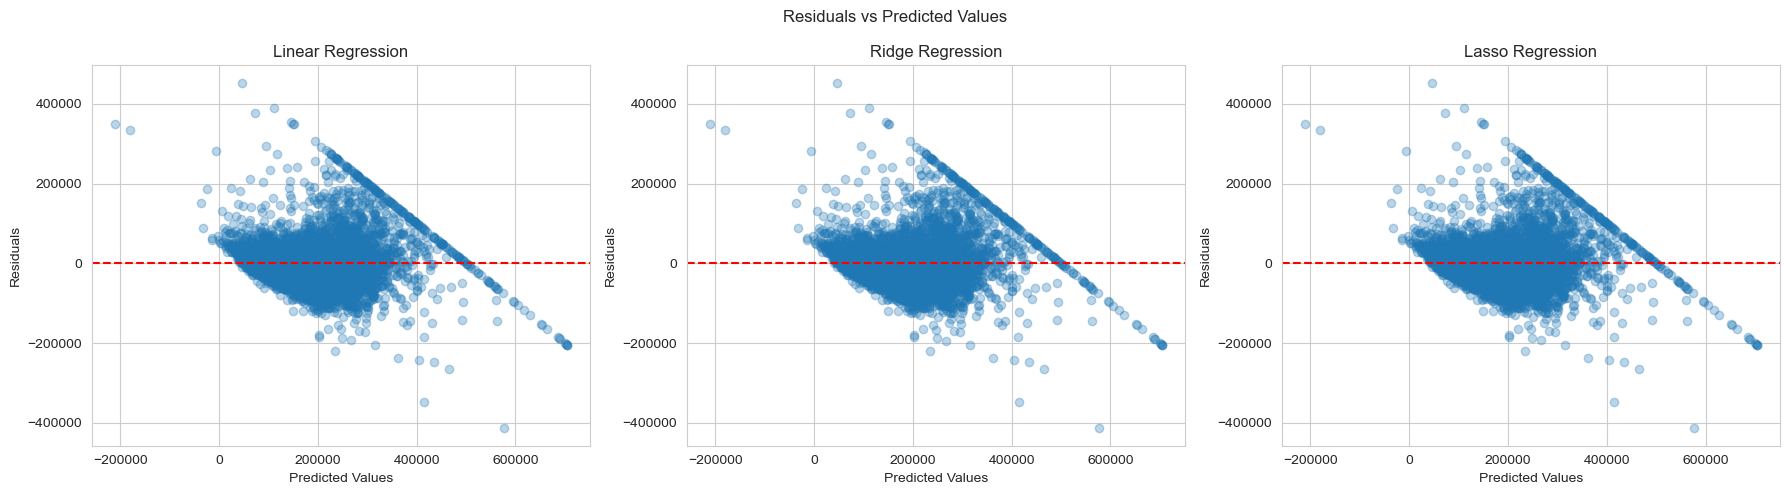

In [32]:

# Residuals vs Predicted

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (model_name, predictions_values) in zip(
    axes, predictions.items()
):
    model_residuals = y_test - predictions_values

    ax.scatter(
        predictions_values,
        model_residuals,
        alpha=0.3
    )

    ax.axhline(
        0,
        color="red",
        linestyle="--"
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Values")
    ax.set_ylabel("Residuals")

plt.suptitle("Residuals vs Predicted Values")
plt.tight_layout()
plt.show()


# Final Project Report – California Housing Price Prediction

# Task 02: California Housing Price Prediction

## 1. Project Overview

The objective of this project is to develop and evaluate machine learning regression models to predict median house values in California using the California Housing dataset.

The project focuses on data exploration, preprocessing, feature engineering, regularization techniques, hyperparameter optimization, and model evaluation.

Three regression algorithms were implemented and compared:
- Linear Regression
- Ridge Regression
- Lasso Regression

## 2. Dataset Description

The California Housing dataset contains information about housing districts in California.

- **Total Records:** 20,640
- **Total Features:** 9 input features
- **Target Variable:** `median_house_value`
- **Data Types:** Numerical and categorical

The dataset includes geographical information, housing characteristics, population statistics, and median income.

The `ocean_proximity` feature represents the proximity of housing districts to the ocean.

## 3. Data Exploration and Analysis

Exploratory Data Analysis (EDA) was performed to understand the dataset structure and identify important patterns.

The analysis included:

- Inspecting dataset dimensions and data types.
- Generating descriptive statistical summaries.
- Identifying missing values.
- Checking duplicate records.
- Visualizing the distribution of median house values.
- Analyzing numerical and categorical feature distributions.
- Exploring correlations between numerical features.
- Visualizing the geographical distribution of house values.

Missing values were handled using `SimpleImputer` within the preprocessing pipeline rather than modifying the original dataset.

## 4. Data Preprocessing

The dataset was divided into input features and the target variable.

An 80/20 train-test split was applied:

- **Training Set:** 16,512 records
- **Testing Set:** 4,128 records

A preprocessing pipeline was created using Scikit-learn's `ColumnTransformer`.

### Numerical Features
- Missing values were replaced using median imputation.
- Features were standardized using `StandardScaler`.

### Categorical Features
- Missing values were replaced using the most frequent value.
- Categorical variables were encoded using `OneHotEncoder`.

Using pipelines ensured that preprocessing operations were fitted on training data only, helping prevent data leakage.

## 5. Feature Engineering

Several meaningful features were created to improve the predictive information available to the models:

- `rooms_per_household`: Average number of rooms per household.
- `bedrooms_per_room`: Ratio of bedrooms to total rooms.
- `population_per_household`: Average population per household.

These engineered ratio features provide additional information about housing density and household characteristics.

## 6. Model Development

Three regression algorithms were trained and evaluated.

### 6.1 Linear Regression

Linear Regression was used as the baseline model. It estimates the relationship between input features and median house values using Ordinary Least Squares (OLS).

### 6.2 Ridge Regression

Ridge Regression applies L2 regularization to penalize large model coefficients and help reduce the impact of multicollinearity.

### 6.3 Lasso Regression

Lasso Regression applies L1 regularization, which can shrink some coefficients to zero and perform implicit feature selection.

## 7. Hyperparameter Optimization

GridSearchCV with 5-fold cross-validation was used to optimize the regularization parameter (`alpha`) for Ridge and Lasso Regression.

The tested alpha values were:

`[0.01, 0.1, 1, 10, 100, 1000]`

The selected hyperparameters were:

- **Ridge Best Alpha:** 1
- **Lasso Best Alpha:** 1

Cross-validation RMSE:

- **Ridge:** 67,847.59
- **Lasso:** 67,848.71

## 8. Model Evaluation

The models were evaluated on the unseen test dataset using three regression metrics:

- **RMSE:** Root Mean Squared Error.
- **MAE:** Mean Absolute Error.
- **R² Score:** Coefficient of Determination.

### Performance Comparison

| Model | RMSE | MAE | R² Score |
|---|---:|---:|---:|
| Linear Regression | 69,127.04 | 49,645.49 | 0.63534 |
| Lasso Regression | 69,128.09 | 49,646.43 | 0.63533 |
| Ridge Regression | 69,134.97 | 49,652.14 | 0.63526 |

### Results Interpretation

Linear Regression achieved the best test performance among the three models.

It obtained:

- **RMSE:** 69,127.04
- **MAE:** 49,645.49
- **R² Score:** 0.63534

The R² score indicates that the model explains approximately 63.5% of the variation in median house values.

The performance differences between the three models were very small, indicating similar predictive performance on the test dataset.

## 9. Model Visualization and Residual Analysis

Several visualizations were prepared to assess model performance:

- Actual vs. Predicted plots to compare predicted values with actual house prices.
- Residual distribution plots to examine prediction errors.
- Residuals vs. Predicted plots to identify potential patterns and changing error variance.

These visualizations provide additional insight into model accuracy and limitations beyond numerical evaluation metrics.

## 10. Challenges and Limitations

Some challenges and limitations identified during the project include:

- Missing values in the `total_bedrooms` feature.
- Potential multicollinearity among numerical predictors.
- Differences in feature distributions and scales.
- The limitations of linear models in capturing complex non-linear relationships.
- The relatively high prediction errors for some housing districts.

Regularization techniques were explored to reduce the impact of correlated features and improve model stability.

## 11. Conclusion

This project demonstrated a complete machine learning regression workflow, starting from data exploration and preprocessing through model training, hyperparameter optimization, and evaluation.

Three regression models were successfully implemented and compared.

Linear Regression achieved the best test results, with an RMSE of 69,127.04, an MAE of 49,645.49, and an R² score of 0.63534.

Although Ridge and Lasso Regression achieved very similar results, regularization did not provide a measurable improvement over the baseline Linear Regression model in this experiment.

Overall, the project provided practical experience in regression modeling, feature engineering, preprocessing pipelines, cross-validation, and model evaluation.

## 12. Future Improvements

Potential future improvements include:

- Testing non-linear regression algorithms such as Random Forest and Gradient Boosting.
- Exploring additional interaction features.
- Performing more detailed multicollinearity analysis.
- Applying feature selection techniques.
- Conducting further hyperparameter optimization.
- Evaluating additional methods for handling outliers and skewed distributions.

## 13. Technologies and Libraries

The project was implemented using Python and the following libraries:

- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Jupyter Notebook

---

**Project:** California Housing Price Prediction  
**Internship:** Datheon – Machine Learning & Data Science Internship  
**Task:** Task 02 – Regression  
**Target Variable:** `median_house_value`  
**Best Performing Model:** Linear Regression  
**Test R² Score:** 0.63534